# P1.2 — The MRI Scanner: magnet, gradients, RF coils and computer

**Part:** Pass 1 — The big picture (notebook 2 of 5) · **Reading time:** ~45 min · **Previous:** [P1.1 What MRI Measures](P1.1_What_MRI_Measures.ipynb) · **Next:** [P1.3 From Signal to Image](P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb), [Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb)

**Why this notebook matters.** P1.1 described the physics: polarize, excite, listen. This notebook opens the scanner
and shows which piece of hardware does which job — and why each piece is an engineering *tour de force*. An MRI
scanner combines a 3-tesla magnet that is uniform to a few parts per million, gradient coils driven with ~900 A and
~2000 V that switch in a fraction of a millisecond, a kilowatt radio transmitter, and a receiver that detects
nanovolts — all in one room, around a living patient. Most limits on image quality, speed and safety come from these
components.

## Learning goals

1. Name the main components of an MRI system (main magnet, gradient coils, RF transmit and receive coils, electronics and computer) and the job of each.
2. Explain why the main magnet is superconducting, what liquid helium and a **quench** are, and what **homogeneity in ppm** means.
3. Explain what gradient coils do and quote typical **amplitudes** (mT/m) and **slew rates** (T/m/s); explain acoustic noise, nerve stimulation and eddy currents.
4. Explain RF transmission, coil tuning, **SAR**, and why high fields give inhomogeneous RF.
5. Explain why receive coils are arrays of small loops, how small the signal is, and what the receive chain (preamplifier, demodulator, ADC) has to achieve.
6. Answer: *Why is MRI so loud? Why are ferromagnetic objects dangerous? Why does a 7 T scanner not simply give 2.3× better images than 3 T?*

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x,y,z$ | position; $z$ along the bore axis / $B_0$ | m | isocenter = magnet center = (0,0,0) |
| $B_0$ | main static field | T | 1.5 T, 3 T |
| $\Delta B_0$ | deviation of the static field from $B_0$ (inhomogeneity) | T | quoted in ppm of $B_0$ |
| ppm | parts per million, $10^{-6}$ | – | 1 ppm at 3 T = 3 µT ≙ 128 Hz |
| $B_z$ | $z$-component of the total field at a point | T | $B_z = B_0 + G_x x + G_y y + G_z z$ |
| $\vec G=[G_x,G_y,G_z]$ | gradient: rate of change of $B_z$ along $x$, $y$, $z$ | T/m | 20–80 mT/m |
| $SR$ | slew rate: maximum rate of change of $G$ | T/m/s | 100–200 T/m/s |
| $dB/dt$ | rate of change of the field at a point (nerve stimulation) | T/s | limit ~ tens of T/s |
| $B_1$, $B_1^+$ | RF transmit field (strength; co-rotating component that tips spins) | T | 1–25 µT |
| $B_1^-$ | receive sensitivity of a coil (field it would make per unit current, by reciprocity) | T/A | |
| $f_0=\bar\gamma B_0$ | Larmor frequency; $\bar\gamma$ = 42.58 MHz/T for ¹H | Hz | 127.7 MHz at 3 T |
| $\omega_0 = 2\pi f_0$ | angular Larmor frequency | rad/s | |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $I_c$ | electric current in a coil | A | magnet ~ 300–700 A; gradients up to ~900 A |
| $N_{turns}$ | number of wire turns | – | |
| $L$, $C$, $R_{coil}$ | inductance, capacitance, resistance | H, F, Ω | |
| $Q$ | quality factor of a resonant coil (sharpness of tuning) | – | unloaded ~100–300, loaded ~10–50 |
| $V$ | voltage | V | gradient amplifier ~2000 V |
| $E_{mag}$ | energy stored in the magnetic field | J | several MJ |
| $F$ | force | N | |
| $SAR$ | specific absorption rate: RF power absorbed per kg of tissue | W/kg | limit 2 W/kg whole body (normal mode), 3.2 W/kg head |
| $\varepsilon_r$ | relative permittivity of tissue | – | ≈ 50–70 at 64–300 MHz |
| $c$ | speed of light in vacuum | m/s | $3.0\times10^8$ |
| $\lambda$ | wavelength of the RF field in tissue | m | ≈ 30 cm at 3 T |
| $k_B$, $T$ | Boltzmann constant; absolute temperature | J/K, K | $1.381\times10^{-23}$; 310 K |
| $\Delta f_{BW}$ | receiver bandwidth (in the noise formula) | Hz | 10–500 kHz |
| $v_n$ | rms thermal-noise voltage | V | tens of nV |
| $M_0$ | equilibrium magnetization (P1.1) | A/m | 0.009 A/m water at 3 T |
| $s(t)$ | received signal voltage | V | nV–µV |

**Symbol clashes:** $T$ alone = temperature, "T" after a number = tesla. $I_c$ is used for current so as not to clash with the spin number $I$.
$R_{coil}$ is a resistance (elsewhere $R$ is the acceleration factor).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. What is inside the doughnut?

![MRI system diagram](../images/MRI_system_diagram.png)

*Cut-away of a typical cylindrical MRI scanner (image: National High Magnetic Field Laboratory, via Larson's book).
From outside to inside: main magnet (in its cryostat), gradient coils, RF body coil, patient table; local receive coils
are placed on the patient.*

| Component | Job (from P1.1) | Key spec | Typical numbers |
|---|---|---|---|
| **Main magnet** | **Polarization**: create $B_0$ | strength, homogeneity, stability | 1.5 or 3 T; < ~5 ppm over a 40–50 cm sphere; drift < 0.1 ppm/h |
| **Gradient coils** (3: $x,y,z$) | **Spatial encoding**: make $B_z$ vary linearly with position | amplitude, slew rate, linearity, duty cycle | 40–80 mT/m, 100–200 T/m/s |
| **RF transmit coil** | **Excitation**: create $B_1^+$ at $f_0$ | uniformity, power | $B_1$ up to ~25 µT, amplifier 15–35 kW peak |
| **RF receive coils** | **Acquisition**: detect the precessing $M_{xy}$ | sensitivity (SNR), # channels | 8–64 (up to 128) channels |
| **Electronics + computer** | timing (pulse sequence), digitization, reconstruction | timing precision, ADC dynamic range | µs timing; ≥ 16-bit ADCs; GPU reconstruction |

The scan room itself is part of the system: an **RF-shielded room (Faraday cage)** keeps radio stations, phones and
lamps out of the receiver, and sometimes **magnetic shielding** (iron) contains the stray field.

➡️ **Go deeper:** [B1 MRI System](../pass2_deep_dive/B1_MRI_System.ipynb) · [B2 Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) · [RP1 Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb)

## 2. The main magnet

### 2.1 How to make 3 tesla: lots of current in a coil

A current $I_c$ in a wire creates a magnetic field around it; wind the wire into a long coil (**solenoid**) and the
fields of all turns add up into a strong, nearly uniform field inside:

$$B_0 \approx \mu_0\,\frac{N_{turns}}{\ell}\,I_c .$$

*In words:* the field inside a long solenoid is proportional to the number of turns per metre of length and to the
current. $\mu_0 = 4\pi\times10^{-7}$ T m/A, $N_{turns}$ = number of turns, $\ell$ = coil length [m], $I_c$ = current [A].

| ![Field of a loop, small current](../images/loop_small_current.png) | ![Field of a solenoid](../images/solenoid_small_current.png) |
| :-: | :-: |
| Field lines of a single current loop | Many loops (a solenoid): uniform field inside |

In [2]:
B0, ell = 3.0, 1.6                         # target field [T], magnet length [m]
amp_turns = B0 * ell / mt.MU0              # N_turns * I_c needed (long-solenoid estimate)
I_c = 500.0                                # a typical persistent current [A]
print(f"Ampere-turns needed for {B0} T over {ell} m: {amp_turns/1e6:.1f} MA-turns")
print(f"At I = {I_c:.0f} A that is {amp_turns/I_c:,.0f} turns; with a 0.9 m diameter, "
      f"~{amp_turns/I_c*np.pi*0.9/1e3:.0f} km of wire")

Ampere-turns needed for 3.0 T over 1.6 m: 3.8 MA-turns
At I = 500 A that is 7,639 turns; with a 0.9 m diameter, ~22 km of wire


Millions of ampere-turns through tens of kilometres of wire: with copper, the resistive heating would be enormous
(resistive magnets are practical only up to ~0.5 T). Clinical magnets therefore use **superconducting** wire,
typically niobium–titanium (NbTi) filaments in a copper matrix, which has *zero* electrical resistance below ~9 K.
The coil sits in a bath of **liquid helium** at 4.2 K (−269 °C) inside a vacuum-insulated vessel (**cryostat**).

Once the current is "ramped up", a superconducting switch closes the circuit and the current circulates **forever**
without a power supply (**persistent mode**). That is why *the magnet is always on*, even at night and during a power
cut.

> **🔧 Engineering reality:** Older magnets hold 1000–2000 litres of liquid helium; a **cold head** (cryocooler,
> the rhythmic "chirping" you hear in the scan room) re-condenses the boil-off. Helium is a scarce, expensive resource,
> so newer "sealed" or low-helium designs need only a few litres. Typical whole-body magnets weigh several tonnes
> (≈ 4–12 t). A rough industry rule of thumb is ~US$1 million per tesla for a complete system.

### 2.2 Homogeneity: parts per million

The field must be *extremely* uniform: if $B_0$ varied across the body, the spins would precess at different
frequencies, the frequency-based position encoding (P1.3) would be distorted and signal would dephase faster
($T_2^*$, P1.1). Specs are given in **ppm** (parts per million) over a **diameter of spherical volume (DSV)**, e.g.
"< 2 ppm over 40 cm DSV". 1 ppm at 3 T means $\Delta B_0 = 3$ µT, i.e. a frequency error of 127.7 Hz.

A plain solenoid is *not* uniform enough: its field drops towards the ends. Real magnets use several coil blocks
whose positions and currents are optimized. Let's see this with the exact on-axis field of current loops
(`mt.loop_field_on_axis`).

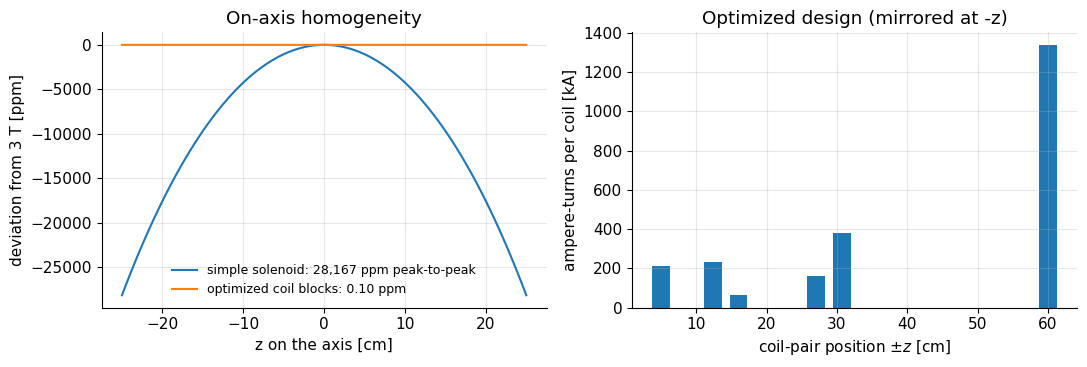

1 ppm at 3 T = 127.7 Hz; the simple solenoid's error corresponds to 3.6 MHz across 50 cm


In [3]:
from scipy.optimize import nnls

R_mag = 0.45                                   # coil radius [m]
z = np.linspace(-0.25, 0.25, 101)              # region of interest on the axis: +-25 cm

# (a) a simple solenoid: 161 equal loops spread over 1.6 m
z_loops = np.linspace(-0.8, 0.8, 161)
B_sol = sum(mt.loop_field_on_axis(z - zl, R_mag, 1.0) for zl in z_loops)
B_sol *= 3.0 / B_sol[50]                       # scale the current so that B(0) = 3 T

# (b) "designed" magnet: 16 candidate coil pairs at +-z_k, non-negative currents chosen by least squares
z_pairs = np.linspace(0.05, 0.6, 16)
A = np.stack([mt.loop_field_on_axis(z - p, R_mag, 1) + mt.loop_field_on_axis(z + p, R_mag, 1) for p in z_pairs], 1)
amp_turns_k, _ = nnls(A, np.full(z.size, 3.0))   # ampere-turns in each coil pair
B_des = A @ amp_turns_k

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(z*100, (B_sol/3 - 1)*1e6, label=f"simple solenoid: {np.ptp(B_sol)/3*1e6:,.0f} ppm peak-to-peak")
ax[0].plot(z*100, (B_des/3 - 1)*1e6, label=f"optimized coil blocks: {np.ptp(B_des)/3*1e6:.2f} ppm")
ax[0].set(xlabel="z on the axis [cm]", ylabel="deviation from 3 T [ppm]", title="On-axis homogeneity")
ax[0].legend(fontsize=9)
ax[1].bar(z_pairs*100, amp_turns_k/1e3, width=2.5)
ax[1].set(xlabel="coil-pair position $\\pm z$ [cm]", ylabel="ampere-turns per coil [kA]", title="Optimized design (mirrored at -z)")
plt.tight_layout(); plt.show()
print(f"1 ppm at 3 T = {mt.larmor_frequency(3.0)*1e-6:.1f} Hz; the simple solenoid's error corresponds to "
      f"{np.ptp(B_sol)/3*mt.larmor_frequency(3.0)/1e6:.1f} MHz across 50 cm")

*Interpretation:* a plain 1.6 m solenoid deviates by ~3 % (tens of thousands of ppm) over ±25 cm — useless for imaging.
Putting more current near the ends (the big end coil) flattens the field to well below 1 ppm on the axis. Real designs
must achieve this in 3D (not only on the axis), with short bores for patient comfort, and with manufacturing tolerances
of fractions of a millimetre.

What the factory cannot achieve is fixed on site by **shimming**: **passive shims** (small iron pieces placed in trays
in the bore) and **active shims** (extra coils, adjusted for every patient, because the patient's own tissue/air
susceptibility distorts the field by several ppm).

### 2.3 Fringe field, shielding and the "5-gauss line"

The field does not stop at the end of the bore. Far away a magnet looks like a giant bar magnet (a *dipole*) whose
field decays like $1/\text{distance}^3$. Modern magnets are **actively shielded**: a second set of superconducting
coils with a larger radius carries current in the *opposite* direction and cancels the dipole far field.
The safety boundary is the **0.5 mT (5 gauss) line**, beyond which pacemakers are considered safe; access inside it is
controlled.

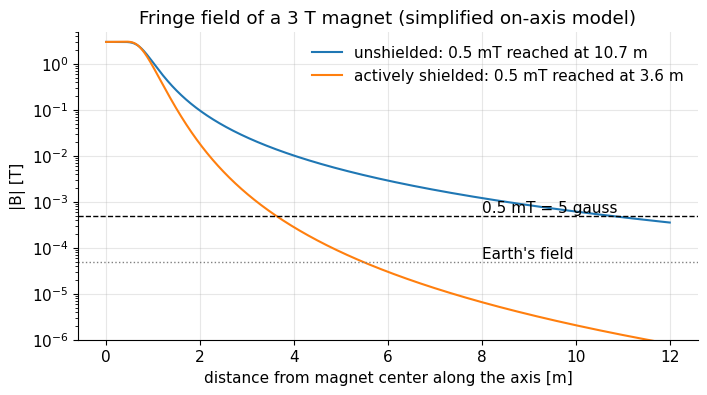

In [4]:
z_far = np.linspace(0, 12, 2401)                       # distance along the axis [m]

def B_axis(zz, shielded):
    B = sum(c*(mt.loop_field_on_axis(zz - p, R_mag, 1) + mt.loop_field_on_axis(zz + p, R_mag, 1))
            for c, p in zip(amp_turns_k, z_pairs))
    if shielded:                                       # 4 shield loops at radius 0.85 m, opposite current,
        R_sh, z_sh = 0.85, np.array([-0.75, -0.25, 0.25, 0.75])
        I_sh = -2*amp_turns_k.sum()*R_mag**2 / (len(z_sh)*R_sh**2)   # chosen so total dipole moment = 0
        B = B + sum(I_sh*mt.loop_field_on_axis(zz - p, R_sh, 1) for p in z_sh)
    return B

plt.figure(figsize=(8, 4))
for sh, lab in [(False, "unshielded"), (True, "actively shielded")]:
    B = B_axis(z_far, sh)
    B *= 3.0 / B_axis(np.array([0.0]), sh)[0]          # re-scale current so both give 3 T at the center
    d5 = z_far[np.abs(B) > 5e-4].max()
    plt.semilogy(z_far, np.abs(B), label=f"{lab}: 0.5 mT reached at {d5:.1f} m")
plt.axhline(5e-4, color="k", ls="--", lw=1); plt.text(8, 6e-4, "0.5 mT = 5 gauss")
plt.axhline(50e-6, color="gray", ls=":", lw=1); plt.text(8, 6e-5, "Earth's field")
plt.xlabel("distance from magnet center along the axis [m]"); plt.ylabel("|B| [T]"); plt.ylim(1e-6, 5)
plt.title("Fringe field of a 3 T magnet (simplified on-axis model)"); plt.legend(); plt.show()

*Interpretation:* without shielding the 5-gauss line would be > 10 m away along the axis; the opposing shield coil
pulls it in to a few metres, so the magnet fits into a normal hospital room. (Our toy shield would also spoil the
homogeneity; real designs optimize both coil sets together.) Note how steeply the field rises near the bore entrance:
the large **spatial gradient** of the fringe field is what pulls ferromagnetic objects in (P1.5, safety).

### 2.4 Stored energy and the quench

The magnetic field stores energy, $E_{mag} = \int \frac{B^2}{2\mu_0}\,dV$ (energy density $B^2/2\mu_0$ in J/m³,
integrated over volume $V$).

In [5]:
energy_density = 3.0**2 / (2*mt.MU0)                # [J/m^3] at 3 T
bore_volume = np.pi * 0.45**2 * 1.6                  # rough volume of the high-field region [m^3]
E = energy_density * bore_volume
print(f"Energy density at 3 T: {energy_density/1e6:.1f} MJ/m^3; inside the bore alone ~{E/1e6:.0f} MJ")
print(f"(a 10-tonne truck at 100 km/h has {0.5*1e4*(100/3.6)**2/1e6:.1f} MJ of kinetic energy)")
He_liquid_L = 1500
print(f"{He_liquid_L} L liquid helium -> ~{He_liquid_L*750/1000:,.0f} m^3 of helium gas at room temperature (expansion ~1:750)")

Energy density at 3 T: 3.6 MJ/m^3; inside the bore alone ~4 MJ
(a 10-tonne truck at 100 km/h has 3.9 MJ of kinetic energy)
1500 L liquid helium -> ~1,125 m^3 of helium gas at room temperature (expansion ~1:750)


If a small part of the coil loses superconductivity (e.g. a defect, or a deliberate emergency shutdown), it suddenly
has resistance, heats up, and the normal zone spreads: the stored megajoules turn into heat within seconds and boil
off the helium explosively. This is a **quench**. A **quench pipe** must vent the gas outside the building, because
helium displaces oxygen (asphyxiation risk) and the cold gas can cause frostbite. Quenching on purpose (the red
"magnet stop" button) is reserved for life-threatening emergencies, e.g. a person pinned by a metal object; re-cooling
and re-ramping a magnet costs days and tens of thousands of euros of helium.

➡️ **Go deeper:** [B3 Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb) (superconductors, cryogenics, quench, shimming, siting) · [B2 Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) · [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb) · [RP1 Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb)

## 3. The gradient system

### 3.1 What a gradient does

Gradient coils add a small field along $z$ whose strength varies *linearly* with position:

$$B_z(x,y,z) = B_0 + G_x\,x + G_y\,y + G_z\,z .$$

*In words:* with a gradient $G_x$ switched on, spins at position $x$ see $B_0$ plus $G_x x$, so their Larmor frequency
becomes $f(x) = \bar\gamma\,(B_0 + G_x x)$: **frequency now tells you position**. $G_x, G_y, G_z$ are in T/m; three
independent coils (one per axis) can be combined to point the gradient in any direction.

> **⚠️ Common confusion:** all three gradient coils change only the **$z$-component** of the field (the one along
> $B_0$); "$G_x$" means "$B_z$ changes along $x$", not "a field pointing along $x$". (They also create small transverse
> "concomitant" fields, which are negligible at high $B_0$.)

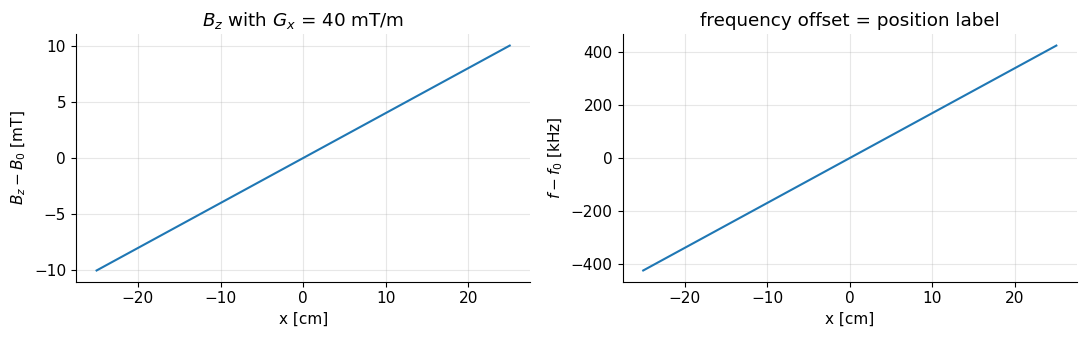

gamma_bar*G = 1703 Hz per mm; at x = 10 cm: 170 kHz (only 1333 ppm of B0)


In [6]:
x = np.linspace(-0.25, 0.25, 201)                   # position across the bore [m]
G = 40e-3                                           # 40 mT/m, a typical clinical maximum
f_offset = mt.GAMMA_BAR * G * x                     # frequency offset from f0 [Hz]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(x*100, (3.0 + G*x)*1e3 - 3000)
ax[0].set(xlabel="x [cm]", ylabel="$B_z - B_0$ [mT]", title="$B_z$ with $G_x$ = 40 mT/m")
ax[1].plot(x*100, f_offset/1e3)
ax[1].set(xlabel="x [cm]", ylabel="$f - f_0$ [kHz]", title="frequency offset = position label")
plt.tight_layout(); plt.show()
print(f"gamma_bar*G = {mt.GAMMA_BAR*G/1e3:.0f} Hz per mm; at x = 10 cm: {mt.GAMMA_BAR*G*0.1/1e3:.0f} kHz "
      f"(only {G*0.1/3*1e6:.0f} ppm of B0)")

*Interpretation:* even the maximum gradient changes the field by only ~±10 mT over a ±25 cm body (about 0.3 % of
$B_0$), but that is a frequency spread of hundreds of kHz — easily resolved by the receiver.

The simplest $z$-gradient coil is a **Maxwell pair**: two loops with opposite currents, separated by $\sqrt3$ times
their radius. (The $x$ and $y$ coils use "saddle" or "fingerprint" shaped windings.)

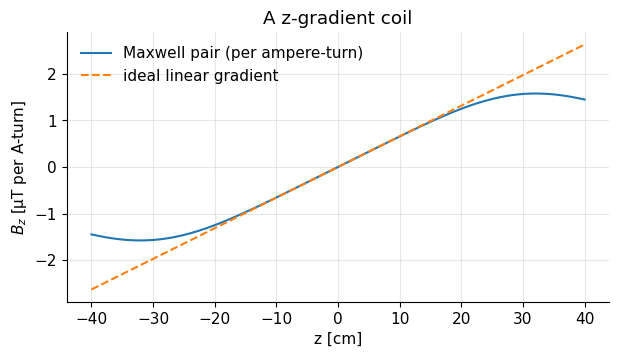

efficiency: 6.58 uT/m per ampere-turn -> 40 mT/m needs 6,080 ampere-turns (e.g. 10 turns x 600 A)


In [7]:
R_g = 0.35                                          # gradient-coil radius [m]
d = np.sqrt(3)/2 * R_g                              # loops at z = +-d (Maxwell condition)
zg = np.linspace(-0.4, 0.4, 401)
Bz_pair = mt.loop_field_on_axis(zg - d, R_g, 1.0) - mt.loop_field_on_axis(zg + d, R_g, 1.0)  # +I at z=+d, -I at z=-d; per ampere-turn
eff = np.gradient(Bz_pair, zg)[200]                 # gradient at the center [T/m per A-turn]

plt.figure(figsize=(7, 3.5))
plt.plot(zg*100, Bz_pair*1e6, label="Maxwell pair (per ampere-turn)")
plt.plot(zg*100, eff*zg*1e6, "--", label="ideal linear gradient")
plt.xlabel("z [cm]"); plt.ylabel("$B_z$ [µT per A-turn]"); plt.legend(); plt.title("A z-gradient coil"); plt.show()
print(f"efficiency: {eff*1e6:.2f} uT/m per ampere-turn -> 40 mT/m needs {40e-3/eff:,.0f} ampere-turns "
      f"(e.g. {40e-3/eff/600:.0f} turns x 600 A)")

*Interpretation:* the field is linear only near the center (roughly ±15 cm here); beyond that the gradient
"flattens out". Real gradient coils are linear over ~40–50 cm, and the remaining **gradient non-linearity** distorts
images near the edge of a large field of view (corrected in software, see P1.5).

### 3.2 Amplitude, slew rate and the trapezoid

Gradients are switched on and off thousands of times per second. Because the coil has inductance, the current cannot
jump instantly; the waveforms are **trapezoids** whose ramp steepness is the **slew rate** $SR$ (T/m/s).
Ramp time = $G_{max}/SR$, e.g. 40 mT/m ÷ 200 T/m/s = 0.2 ms.

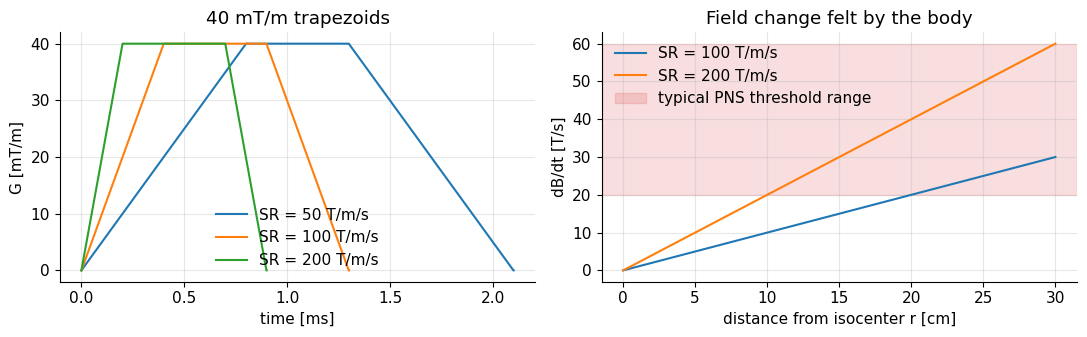

In [8]:
def trapezoid(G_amp, flat_time, slew, dt=1e-6):
    """Gradient trapezoid [T/m] sampled every dt [s]: ramp up at `slew` [T/m/s], flat top, ramp down."""
    n_ramp = int(round(abs(G_amp)/slew/dt))
    ramp = np.linspace(0, G_amp, n_ramp, endpoint=False)
    return np.concatenate([ramp, np.full(int(round(flat_time/dt)), G_amp), ramp[::-1], [0.0]])

dt = 1e-6
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for SR in [50, 100, 200]:
    g = trapezoid(40e-3, 0.5e-3, SR)
    ax[0].plot(np.arange(g.size)*dt*1e3, g*1e3, label=f"SR = {SR} T/m/s")
ax[0].set(xlabel="time [ms]", ylabel="G [mT/m]", title="40 mT/m trapezoids"); ax[0].legend()

# dB/dt experienced at distance r from isocenter during the ramp: dB/dt = SR * r
r = np.linspace(0, 0.3, 50)
for SR in [100, 200]:
    ax[1].plot(r*100, SR*r, label=f"SR = {SR} T/m/s")
ax[1].axhspan(20, 60, color="C3", alpha=0.15, label="typical PNS threshold range")
ax[1].set(xlabel="distance from isocenter r [cm]", ylabel="dB/dt [T/s]", title="Field change felt by the body"); ax[1].legend()
plt.tight_layout(); plt.show()

*Interpretation:* faster slewing gives shorter ramps and therefore faster imaging (P1.5). But the body feels the
*change* of the field: at 25–30 cm from the center (shoulders, abdomen periphery) a 200 T/m/s ramp creates
$dB/dt$ ≈ 50–60 T/s. Rapidly changing fields induce electric fields in tissue that can stimulate nerves —
**peripheral nerve stimulation (PNS)**, felt as twitching or tingling. The threshold depends on the ramp duration and on
the body region (the band above is only indicative). **In modern scanners it is PNS — not the amplifier — that limits
how fast gradients may switch.**

### 3.3 Power, heat, noise and eddy currents

> **🔧 Engineering reality — power:** a gradient coil has an inductance of the order of 1 mH. Ramping ~600 A in 0.2 ms
> needs $V = L\,dI_c/dt$ ≈ 1 mH × 3×10⁶ A/s = 3000 V. Gradient amplifiers are therefore ~2000 V / ~900 A devices with
> megawatt peak power, and the coils are water-cooled because $I_c^2 R_{coil}$ heating at high duty cycles reaches
> many kW.

**Why MRI is loud.** A wire carrying current $I_c$ in a field $B_0$ feels the **Lorentz force** $F = I_c\,\ell\,B_0$
(per wire length $\ell$, when the wire is perpendicular to the field): 600 A × 1 m × 3 T = 1800 N — the weight of
~180 kg — and it reverses with every gradient switch. The coil vibrates like a loudspeaker. The sound spectrum is the
spectrum of the gradient waveform, filtered by the mechanical resonances of the coil.

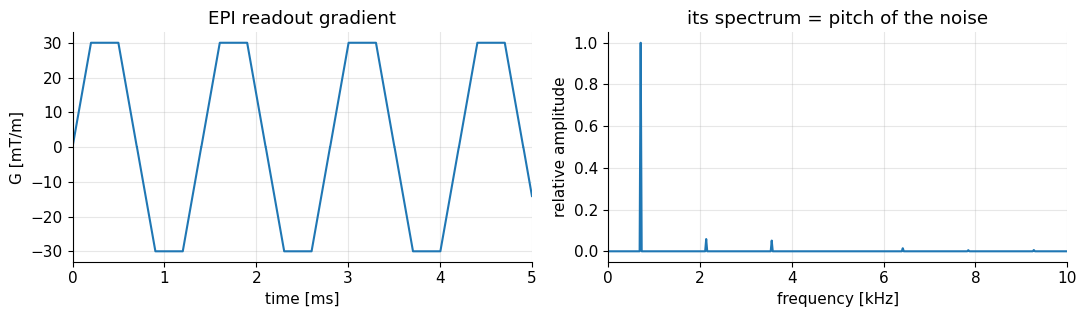

fundamental frequency: 713 Hz  (in the most sensitive range of human hearing)


In [9]:
# An EPI-like readout: alternating +-trapezoids (each 0.7 ms long) -> a periodic waveform at ~0.7 kHz
lobe = trapezoid(30e-3, 0.30e-3, 150)
g_epi = np.concatenate([lobe if k % 2 == 0 else -lobe for k in range(64)])
t = np.arange(g_epi.size)*dt
spec = np.abs(np.fft.rfft(g_epi)); freqs = np.fft.rfftfreq(g_epi.size, dt)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(t*1e3, g_epi*1e3); ax[0].set(xlim=(0, 5), xlabel="time [ms]", ylabel="G [mT/m]", title="EPI readout gradient")
ax[1].plot(freqs/1e3, spec/spec.max()); ax[1].set(xlim=(0, 10), xlabel="frequency [kHz]", ylabel="relative amplitude",
                                              title="its spectrum = pitch of the noise")
plt.tight_layout(); plt.show()
print(f"fundamental frequency: {freqs[np.argmax(spec)]:.0f} Hz  (in the most sensitive range of human hearing)")

*Interpretation:* this EPI readout drives the coil at ~0.7 kHz plus odd harmonics (real EPI: 0.5–2 kHz), right where our ears are most
sensitive. Sound pressure levels above 110 dB(A) — rock-concert level — occur; **hearing protection is mandatory**.
Quiet sequences use slow, smooth gradient waveforms (at the cost of speed).

**Eddy currents.** A changing magnetic field induces currents in any nearby conductor — especially the metal walls of
the cryostat. These **eddy currents** create their own field that opposes the change and decays over µs–ms, so the
actual gradient lags behind the commanded one. Cures: **actively shielded gradient coils** (an outer winding cancels the
field outside the coil, reducing eddy currents ~100-fold) and **pre-emphasis** (the amplifier deliberately overshoots
so that the *sum* has the right shape).

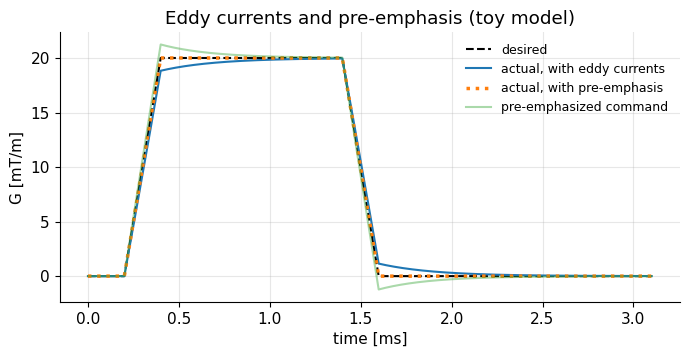

In [10]:
from scipy.signal import lfilter
g_cmd = np.concatenate([np.zeros(200), trapezoid(20e-3, 1.0e-3, 100), np.zeros(1500)])
tt = np.arange(g_cmd.size)*dt
tau, alpha = 0.3e-3, 0.08                     # eddy-current time constant [s] and relative strength (illustrative)
a = np.exp(-dt/tau)

def eddy(g):
    """Simple 1st-order model: eddy field = -alpha * (dG/dt convolved with exp(-t/tau)) * tau."""
    dg = np.diff(g, prepend=0.0)
    return -alpha * lfilter([1.0], [1.0, -a], dg)

g_act = g_cmd + eddy(g_cmd)
g_pre = g_cmd.copy()
for _ in range(5):                            # pre-emphasis: iterate so that (g_pre + eddy(g_pre)) ~ g_cmd
    g_pre = g_cmd - eddy(g_pre)
plt.figure(figsize=(8, 3.5))
plt.plot(tt*1e3, g_cmd*1e3, "k--", label="desired")
plt.plot(tt*1e3, g_act*1e3, label="actual, with eddy currents")
plt.plot(tt*1e3, (g_pre + eddy(g_pre))*1e3, ":", lw=2.5, label="actual, with pre-emphasis")
plt.plot(tt*1e3, g_pre*1e3, alpha=0.4, label="pre-emphasized command")
plt.xlabel("time [ms]"); plt.ylabel("G [mT/m]"); plt.legend(fontsize=9); plt.title("Eddy currents and pre-emphasis (toy model)"); plt.show()

*Interpretation:* eddy currents round off the corners and leave a slowly decaying tail after the gradient is switched
off — errors in the encoded positions show up as image distortion and ghosting (EPI and diffusion imaging are
particularly sensitive). Pre-emphasis overshoots the command so that the actual field is a clean trapezoid again.

➡️ **Go deeper:** [B4 Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) (coil design, inductance, amplifiers, eddy currents, PNS, acoustics) · [F1 Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) · [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)

## 4. RF transmission: the excitation antenna

### 4.1 The body coil and tuning

Excitation needs a magnetic field $B_1$ rotating at $f_0$ in the transverse plane, as *uniform* as possible over the
region being imaged (so every spin gets the same flip angle). The workhorse is the **body coil**, a **birdcage**
resonator built into the bore: two rings connected by 16–32 straight "rungs", with capacitors chosen so that the
currents in the rungs vary sinusoidally around the circumference. That current pattern produces a nearly uniform
transverse field which, when the coil is driven in **quadrature** (two feeds 90° apart), rotates at $f_0$ like the spins.

![Body coil](../images/BODY_coil.png)

*Schematic of a birdcage body coil (from Larson's book).*

Any RF coil is a **resonant circuit**: its inductance $L$ (the copper loops) and its capacitors $C$ form an LC circuit
that responds strongly only near its resonance frequency

$$f_{res} = \frac{1}{2\pi\sqrt{LC}} .$$

*In words:* like tuning an old radio, the capacitance is adjusted until the coil "rings" at the Larmor frequency.
The **quality factor** $Q$ (≈ resonance frequency ÷ width of the peak) says how sharply it is tuned.

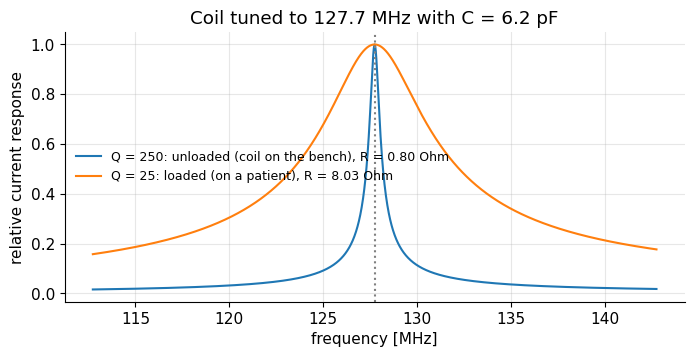

In [11]:
f0 = mt.larmor_frequency(3.0)                  # 127.7 MHz
L = 250e-9                                     # inductance of a ~10 cm loop [H]
C = 1/((2*np.pi*f0)**2 * L)                    # capacitance that tunes it to f0 [F]
f = np.linspace(f0 - 15e6, f0 + 15e6, 2001)
w = 2*np.pi*f
plt.figure(figsize=(8, 3.5))
for Q, lab in [(250, "unloaded (coil on the bench)"), (25, "loaded (on a patient)")]:
    R_coil = 2*np.pi*f0*L/Q                    # series resistance giving this Q [Ohm]
    Z = R_coil + 1j*(w*L - 1/(w*C))            # impedance of the series RLC circuit
    plt.plot(f/1e6, np.abs(R_coil/Z), label=f"Q = {Q}: {lab}, R = {R_coil:.2f} Ohm")
plt.axvline(f0/1e6, color="gray", ls=":")
plt.xlabel("frequency [MHz]"); plt.ylabel("relative current response"); plt.legend(fontsize=9)
plt.title(f"Coil tuned to 127.7 MHz with C = {C*1e12:.1f} pF"); plt.show()

*Interpretation:* on the bench the coil is very sharply tuned. On a patient, the electrically conducting body absorbs
energy and adds resistance, so $Q$ drops ~10×. That is actually a *good* sign for a receive coil: it means the noise
comes mainly from the patient (unavoidable) rather than from the coil's own copper (avoidable). Every patient
"detunes" the coil slightly, which is why coils are re-tuned/matched or designed to be robust to loading.

### 4.2 RF power and SAR

$B_1$ is tiny (µT), but the oscillating magnetic field also induces **electric fields** in the conducting body, which
drive currents and deposit heat. The figure of merit is the **specific absorption rate**, $SAR$ in W/kg.
Roughly, for the same pulse and flip angle, $SAR \propto B_0^2\,B_1^2$ (the induced electric field grows with frequency).

In [12]:
B0s = np.array([0.55, 1.5, 3.0, 7.0])
SAR_rel = (B0s/1.5)**2                         # same flip angle and pulse -> same B1; SAR ~ f0^2 (quasi-static estimate)
for b, s in zip(B0s, SAR_rel):
    print(f"B0 = {b:4.2f} T : relative SAR = {s:5.2f} x (1.5 T)")
print("\nIEC 60601-2-33 normal-mode limits: whole body 2 W/kg, head 3.2 W/kg (averaged over 6 min); "
      "first-level mode: 4 W/kg whole body")

B0 = 0.55 T : relative SAR =  0.13 x (1.5 T)
B0 = 1.50 T : relative SAR =  1.00 x (1.5 T)
B0 = 3.00 T : relative SAR =  4.00 x (1.5 T)
B0 = 7.00 T : relative SAR = 21.78 x (1.5 T)

IEC 60601-2-33 normal-mode limits: whole body 2 W/kg, head 3.2 W/kg (averaged over 6 min); first-level mode: 4 W/kg whole body


Going from 1.5 T to 3 T quadruples the RF heating for the same sequence. Sequences with many large-flip pulses (e.g.
fast spin echo with trains of 180° pulses) quickly hit the SAR limit at 3 T, forcing longer TRs, lower flip angles or
special low-SAR pulses. The scanner predicts SAR from the patient's weight before every scan.

> **🔧 Engineering reality:** the RF power amplifier of a 3 T body coil delivers 15–35 kW peak at 127.7 MHz.
> Over 90 % of the power ends up as heat in the patient; the coil is designed to keep electric fields low, and
> conducting loops (cables, crossed legs, skin-to-skin contact) must be avoided to prevent local burns.

### 4.3 When the wavelength becomes as small as the body

The RF wavelength in tissue is $\lambda = c/(f_0\sqrt{\varepsilon_r})$, where $c$ is the speed of light and
$\varepsilon_r$ the tissue's relative permittivity (water-rich tissue has $\varepsilon_r$ ≈ 50–70, which slows the wave
down ~8×).

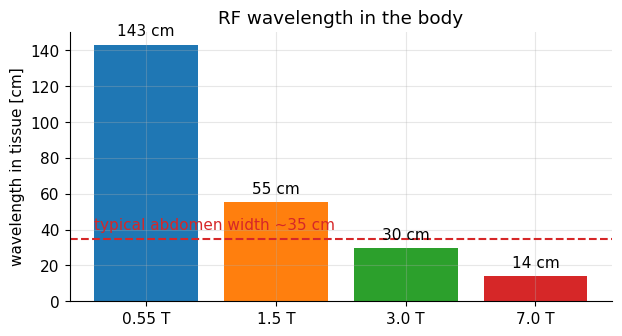

In [13]:
eps_r = {0.55: 80, 1.5: 72, 3.0: 63, 7.0: 52}        # approximate muscle-like permittivity at f0 (decreases with f)
c = 3.0e8
plt.figure(figsize=(7, 3.5))
for b, e in eps_r.items():
    lam = c/(mt.larmor_frequency(b)*np.sqrt(e))
    plt.bar(f"{b} T", lam*100)
    plt.text(list(eps_r).index(b), lam*100 + 5, f"{lam*100:.0f} cm", ha="center")
plt.axhline(35, color="C3", ls="--"); plt.text(-0.4, 40, "typical abdomen width ~35 cm", color="C3")
plt.ylabel("wavelength in tissue [cm]"); plt.title("RF wavelength in the body"); plt.show()

*Interpretation:* at 1.5 T the wavelength is larger than the body and $B_1^+$ is fairly uniform. At 3 T it is about
the size of an abdomen, and standing-wave patterns produce bright and dark regions (**dielectric shading**, flip
angles varying by ±30 % or more). At 7 T the wavelength is ~14 cm and the problem is severe; it is addressed with
**parallel transmission** (several independently driven transmit channels) and special pulses. This, plus SAR, is a
major reason why higher field does not automatically mean better images.

➡️ **Go deeper:** [B5 RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) (amplifier, tuning/matching, birdcage, $B_1^+$ inhomogeneity) · [E1 RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb) · [B6 MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb) · [RP2 Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb)

## 5. RF reception: listening to nanovolts

### 5.1 Coil arrays

A receive coil sees the signal from places it is close to, and noise from *all* the tissue it "sees". A small loop on
the skin is very sensitive nearby but blind deep inside; a big coil sees everything but also collects noise from
everywhere. The best of both worlds is an **array** of many small loops, each with its own receiver channel, combined
in software. Arrays are also the hardware basis of **parallel imaging** (P1.5).

| ![Receive array](../images/TIM_receive_array.png) | ![Spine array](../images/SpineArray.png) |
| :-: | :-: |
| Flexible multi-channel receive arrays | Images from the individual elements of a spine array: each element sees its own region |

Let's compute the sensitivity of four 10-cm loops placed around a head-sized region, using the Biot–Savart helper
`mt.loop_coil_field`. By **reciprocity**, a coil's sensitivity to signal from a point is proportional to the
transverse field $B_1^-$ it would create there if driven with 1 A.

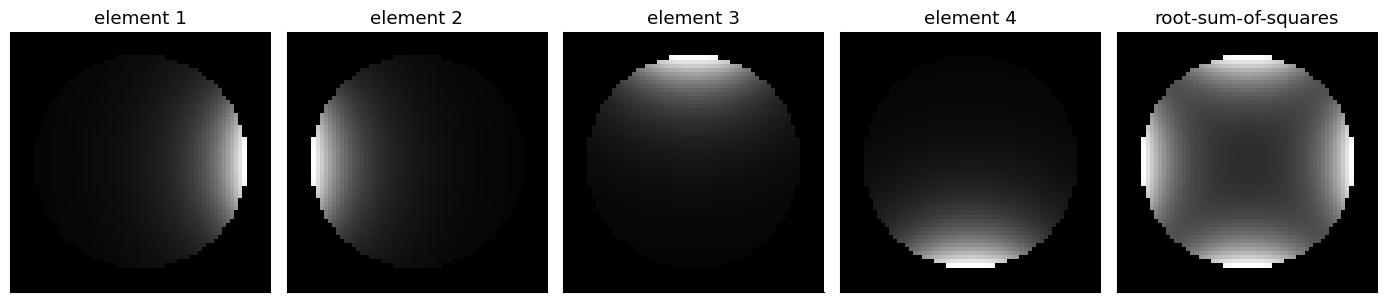

sensitivity at the edge vs center: 12x (element 1)


In [14]:
n = 64
xs = np.linspace(-0.12, 0.12, n)                         # 24 cm x 24 cm transverse plane (z = 0)
X, Y = np.meshgrid(xs, xs[::-1])                         # rows run from +y (top) to -y (bottom)
pts = np.stack([X, Y, np.zeros_like(X)], axis=-1)
coils = [((0.14, 0, 0), "x"), ((-0.14, 0, 0), "x"), ((0, 0.14, 0), "y"), ((0, -0.14, 0), "y")]
sens = []
for center, normal in coils:
    B = mt.loop_coil_field(pts, radius=0.05, current=1.0, center=center, normal=normal)
    sens.append(np.abs(B[..., 0] + 1j*B[..., 1]))        # transverse field magnitude [T per A]
sens = np.array(sens)
head = X**2 + Y**2 < 0.1**2                               # a 20 cm "head"

fig, ax = plt.subplots(1, 5, figsize=(14, 3))
for k in range(4):
    mt.show_image(np.where(head, sens[k], 0), ax=ax[k], title=f"element {k+1}")
mt.show_image(np.where(head, np.sqrt((sens**2).sum(0)), 0), ax=ax[4], title="root-sum-of-squares")
plt.tight_layout(); plt.show()
print(f"sensitivity at the edge vs center: {sens[0][n//2, -6]/sens[0][n//2, n//2]:.0f}x (element 1)")

*Interpretation:* each element is very sensitive near itself and falls off quickly with depth; the combination
(root-sum-of-squares) covers the whole head but is still brighter at the periphery than in the center — the typical
"bright edges" look of array-coil images, usually corrected by an intensity normalization.

### 5.2 How big is the signal, how big is the noise?

A back-of-the-envelope estimate (details in B5): by reciprocity, the voltage induced by a small precessing magnet of
moment $M_0 \times$ (voxel volume) is $\omega_0 \times B_1^-$ (per amp) $\times$ moment. Thermal noise of a coil with
(patient-loaded) resistance $R_{coil}$ over bandwidth $\Delta f_{BW}$ is $v_n = \sqrt{4 k_B T R_{coil} \Delta f_{BW}}$
(Johnson–Nyquist noise).

In [15]:
w0 = 2*np.pi*mt.larmor_frequency(3.0)                   # [rad/s]
M0 = 6.7e28 * mt.GAMMA**2 * mt.HBAR**2 * 3.0 / (4*mt.K_BOLTZMANN*310)   # water magnetization at 3 T [A/m]
voxel = 1e-9                                            # 1 mm^3
b1_per_A = mt.loop_field_on_axis(0.05, 0.05, 1.0)       # field of a 10 cm loop, 5 cm deep, per ampere [T/A]
emf = w0 * b1_per_A * M0 * voxel                        # induced voltage amplitude [V]

R_coil, BW = 2.0, 50e3                                  # loaded coil resistance [Ohm], receiver bandwidth [Hz]
v_n = np.sqrt(4*mt.K_BOLTZMANN*310*R_coil*BW)           # rms noise voltage [V]
print(f"signal from one 1 mm^3 voxel, 5 cm deep : {emf*1e9:5.1f} nV")
print(f"thermal noise ({R_coil} Ohm, {BW/1e3:.0f} kHz)          : {v_n*1e9:5.1f} nV rms")
print(f"per-sample SNR of one voxel ~ {emf/v_n:.1f};  a 256x256 image collects 65536 samples in which every voxel's "
      f"signal adds coherently -> image SNR ~ {emf/v_n*256:.0f} (before T2/T1 losses)")

signal from one 1 mm^3 voxel, 5 cm deep :  33.3 nV
thermal noise (2.0 Ohm, 50 kHz)          :  41.4 nV rms
per-sample SNR of one voxel ~ 0.8;  a 256x256 image collects 65536 samples in which every voxel's signal adds coherently -> image SNR ~ 206 (before T2/T1 losses)


*Interpretation:* the signal of a single voxel is *smaller than the noise* in any one sample! An image is possible
because every one of the tens of thousands of samples contains the signal of every voxel (P1.3 explains how), so the
signal adds up coherently while the noise adds up only as a square root. This estimate also shows the levers for SNR:
more $M_0$ (higher $B_0$), larger voxels, coils closer to the tissue (bigger $B_1^-$), lower noise resistance, narrower
bandwidth, longer sampling (P1.4).

### 5.3 The receive chain and the ADC

1. **Preamplifier** right at the coil: amplifies ~30 dB while adding almost no noise (noise figure < 0.5–1 dB). It also
   helps decouple the array elements from each other.
2. **Active detuning** during transmission: PIN-diode switches detune every receive loop while the body coil transmits
   kilowatts, protecting the preamps (and the patient) — then re-tune within microseconds for reception.
3. **Demodulation**: the signal at $f_0$ is mixed down by $f_0$ (P1.1, Section 7) into complex baseband "I/Q" data.
   Modern scanners digitize at RF or an intermediate frequency and demodulate digitally.
4. **ADC** (analog-to-digital converter): samples every $\Delta t$ (µs) and must handle a huge **dynamic range**: the
   echo peak (center of k-space, P1.3) is orders of magnitude larger than the weak high-resolution data.

k-space dynamic range (max / median) of this small 2D phantom: 592 = 55 dB
(real 3D acquisitions, where the receiver must also resolve the noise floor, need 80-100 dB or more)


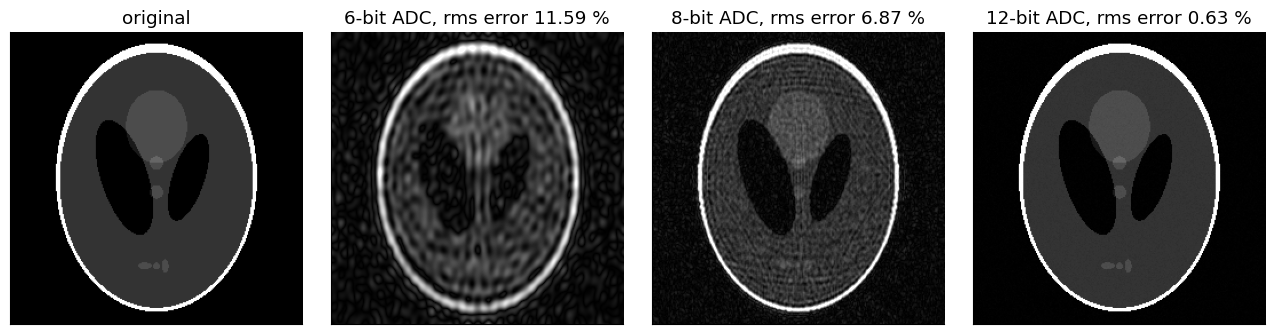

In [16]:
img = mt.shepp_logan(256)
K = mt.fft2c(img)                                       # k-space (P1.3 explains what this is)
dyn = np.abs(K).max() / np.median(np.abs(K))
print(f"k-space dynamic range (max / median) of this small 2D phantom: {dyn:,.0f} = {20*np.log10(dyn):.0f} dB")
print("(real 3D acquisitions, where the receiver must also resolve the noise floor, need 80-100 dB or more)")

def quantize(K, bits):
    fs = max(np.abs(K.real).max(), np.abs(K.imag).max())        # full-scale = biggest sample
    q = 2**(bits-1) - 1
    return (np.round(K.real/fs*q) + 1j*np.round(K.imag/fs*q)) / q * fs

fig, ax = plt.subplots(1, 4, figsize=(13, 3.3))
mt.show_image(img, ax=ax[0], title="original")
for a, bits in zip(ax[1:], [6, 8, 12]):
    rec = np.abs(mt.ifft2c(quantize(K, bits)))
    err = np.sqrt(np.mean((rec - img)**2)) / img.max()
    mt.show_image(rec, ax=a, title=f"{bits}-bit ADC, rms error {100*err:.2f} %", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

*Interpretation:* with too few bits the weak outer k-space samples are rounded away and the image becomes noisy and
blotchy. Real ADCs have ≥ 16 bits (plus variable gain) — and in practice the receiver gain is set so that the thermal
noise itself spans a few bits, which acts as natural dithering.

> **🔧 Engineering reality:** the MRI room is a **Faraday cage** with ~100 dB attenuation at $f_0$. Any leak — a
> door not fully closed, a faulty lamp, an unfiltered cable — injects a narrow-band signal that appears as a bright
> line (**"zipper" artifact**) across the image (P1.5).

➡️ **Go deeper:** [B5 RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) (arrays, preamp decoupling, demodulation, ADC, noise figure) · [B2 Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) (reciprocity, coil profiles) · [G2 Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) · [J4 Advanced SNR](../pass2_deep_dive/J4_Advanced_SNR.ipynb) · [RP2 Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb)

## 6. The computer: sequencer, reconstruction and calibration

The **spectrometer/sequencer** plays the **pulse sequence** (P1.3): it outputs gradient waveforms, RF waveforms
(amplitude, phase, frequency) and ADC gate signals with microsecond precision, all phase-locked to one reference clock.
The **reconstruction computer** (often with GPUs) turns the raw data from up to 128 channels into images, from a simple
FFT to iterative compressed-sensing or deep-learning reconstructions (P1.5).

Before each scan, an automatic **prescan** calibrates the system to the patient:

* **Center frequency**: find $f_0$ exactly (the patient's tissue shifts it by a few ppm).
* **Shimming**: measure a field map and adjust the shim coil currents to make $B_0$ uniform over the region of interest.
* **Transmit gain**: find the RF amplitude that gives a 90° flip in this patient (body size changes loading and $B_1^+$).
* **Receiver gain** and **coil sensitivity maps**: avoid ADC overflow; measure each element's profile for intensity
  correction and parallel imaging.

At installation, engineers additionally shim the magnet passively, calibrate gradient strengths, delays and eddy-current
pre-emphasis, and check the RF shielding.

➡️ **Go deeper:** [B1 MRI System](../pass2_deep_dive/B1_MRI_System.ipynb) · [C1 Pulse Sequence](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) · [F3 Image Reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb)

## 7. The scanner in numbers (cheat sheet)

| Quantity | Typical value | Why it matters |
|---|---|---|
| $B_0$ | 1.5 T / 3 T (7 T research & clinical, 0.55 T low-field) | signal ∝ $B_0$; SAR, artifacts and cost grow with it |
| $f_0$ (¹H) | 63.9 MHz / 127.7 MHz | RF hardware is tuned to this |
| homogeneity | < few ppm over 40–50 cm DSV; ~0.1–1 ppm after patient shim in a small region | distortion, $T_2^*$, fat suppression |
| stored energy | several MJ | quench hazard |
| liquid helium | 1000–2000 L (classic), few L (sealed designs) | cost, supply, quench venting |
| 0.5 mT line | ~2.5–5 m from isocenter (actively shielded) | access control, siting |
| gradient amplitude | 40–80 mT/m (research up to 300 mT/m) | resolution, diffusion weighting, speed |
| slew rate | 100–200 T/m/s | speed; limited by nerve stimulation |
| gradient amplifier | ~2000 V, ~900 A | inductance, power, heat |
| acoustic noise | 100–120 dB(A) for fast sequences | hearing protection |
| RF transmit | $B_1$ ≤ ~25 µT; 15–35 kW peak amplifier | SAR (2 W/kg whole body, 3.2 W/kg head) |
| RF wavelength in tissue | ~55 cm (1.5 T), ~30 cm (3 T), ~14 cm (7 T) | $B_1^+$ inhomogeneity at high field |
| receive channels | 8–64 (up to 128) | SNR, parallel imaging |
| signal per voxel | ~tens of nV (1 mm³, 3 T) | needs low-noise preamps, averaging over many samples |
| ADC | ≥ 16 bit, sampling every 2–20 µs | k-space dynamic range 60–100+ dB |

## Key takeaways

* An MRI scanner = **main magnet** (polarization) + **gradient coils** (spatial encoding) + **RF transmit** (excitation) + **RF receive** (acquisition) + **computer** (sequence timing, reconstruction), inside a Faraday cage.
* The main magnet is a **superconducting** solenoid in liquid helium, always on, uniform to a few **ppm** (1 ppm = 128 Hz at 3 T), storing megajoules; a **quench** releases them as boiling helium.
* **Gradients** (tens of mT/m) make frequency depend on position; their **slew rate** is limited by **nerve stimulation**; Lorentz forces make them **loud**; **eddy currents** distort them unless shielded and pre-emphasized.
* **RF transmission** uses resonant (tuned LC) coils such as the birdcage; RF heating (**SAR**) grows ~ $B_0^2$, and at ≥ 3 T the wavelength in tissue becomes comparable to the body, causing $B_1^+$ inhomogeneity.
* **Reception** uses arrays of small loops with low-noise preamps; a single voxel's signal is nanovolts, below the per-sample noise, and only the coherent accumulation over many samples yields an image.
* The receiver and ADC must cope with a huge **dynamic range** (60–100+ dB) between the center and edges of k-space.

## Check your understanding

**1.** Why is the main magnet kept at 4 K, and why is it "always on"?

<details><summary>Answer</summary>

Only superconducting wire (NbTi below ~9 K, cooled by liquid helium at 4.2 K) can carry the millions of ampere-turns
needed for 1.5–3 T without enormous resistive heating. With zero resistance, the current flows in a closed
superconducting loop (persistent mode) indefinitely without a power supply; turning it off means ramping it down
(days to bring back) or quenching it.

</details>

**2.** A magnet has a homogeneity of 3 ppm over the imaging region at 3 T. What is the resulting range of frequencies?

<details><summary>Answer</summary>

$3\times10^{-6} \times 127.7$ MHz ≈ 383 Hz. If the readout gives, say, 200 Hz per pixel, that is a distortion of up to
~2 pixels (P1.5), and it also speeds up $T_2^*$ decay.

</details>

**3.** Give two reasons why gradients are not simply switched as fast as the amplifier allows.

<details><summary>Answer</summary>

(1) **Peripheral nerve stimulation**: the field change $dB/dt$ (∝ slew rate × distance from isocenter) induces electric
fields in the body that can stimulate nerves. (2) **Acoustic noise and mechanical stress** from Lorentz forces; also
eddy currents and heating grow with faster switching.

</details>

**4.** Why does doubling $B_0$ from 1.5 T to 3 T roughly quadruple SAR for the same sequence?

<details><summary>Answer</summary>

The flip angle depends only on $\gamma B_1 T_{rf}$, so the same $B_1$ is needed at both fields. But the electric field
induced in the body by an oscillating $B_1$ is proportional to its frequency, $f_0 \propto B_0$, and the absorbed power
∝ $|E|^2$, hence ∝ $B_0^2$.

</details>

**5.** Why are modern receive coils arrays of many small loops rather than one large coil?

<details><summary>Answer</summary>

A small loop is very sensitive to nearby tissue and picks up noise only from a small region, giving high local SNR.
An array of many small loops, each with its own receiver, keeps this advantage everywhere near the surface while still
covering a large region. The different sensitivity profiles also enable parallel imaging (acceleration).

</details>

**6.** In a quench, why is the helium vented outside the building?

<details><summary>Answer</summary>

Liquid helium expands ~750-fold when it becomes room-temperature gas; 1500 L of liquid becomes > 1000 m³ of gas, which
would displace the oxygen in the scan room (asphyxiation) and the cold gas could cause frostbite and pressure build-up
(the door may be hard to open).

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapters "MRI System" and "Magnetic Fields in MRI".
Changes: substantially extended with engineering content (superconducting magnet, homogeneity, shielding, quench, gradient electrical/mechanical limits, eddy currents, PNS, RF tuning, SAR, wavelength effects, receive arrays, signal/noise estimates, ADC dynamic range) and Python demos; all numbers are typical orders of magnitude.*